In [4]:
import pandas as pd 
import seaborn as sns 


In [5]:
data = pd.read_csv("smartcart_customers.csv")
df=data.drop("ID",axis=1)


In [6]:
# Data Preprocessing 
df["Income"]=df["Income"].fillna(df["Income"].median())

In [7]:
# when we have date in data we need to convert to numerical values to get max accuracy 

df["Age"]=2026-df["Year_Birth"]
# feature engineering convert date values to numerical 
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
refDate =df["Dt_Customer"].max()
df["Customer_Tenure_Date"]=(refDate-df["Dt_Customer"]).dt.days
# Total Spending Feature 
df.columns
df["Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]
# Total Children 
df["TotalChild"]=df["Kidhome"]+df["Teenhome"]
# Education 
df["Education"].value_counts()

# we have 5 values we convert it to 3 (undergraduate,graduate,postgraduate)
df["Education"]=df["Education"].replace(
    {
        "Basic":"Undergraduate",
        "2n Cycle":"Undergraduate",
        "Graduation":"Graduate",
        "Master":"Postgraduate",
        "PHD":"Postgraduate"
    }
)
df["Marital_Status"].value_counts()

df["Living_With"]=df["Marital_Status"].replace(
    {
        "Married":"Partner",
        "Together":"Partner",
        "Single":"Alone",
        "YOLO":"Alone",
        "Widow":"Alone",
        "Absurd":"Alone",
        "Divorced":"Alone"
    }
)

In [8]:
# now we have created neccessary features we drop unnecesary columns 

cols=["Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer","MntFruits","MntWines","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
df_cleaned=df.drop(cols,axis=1)


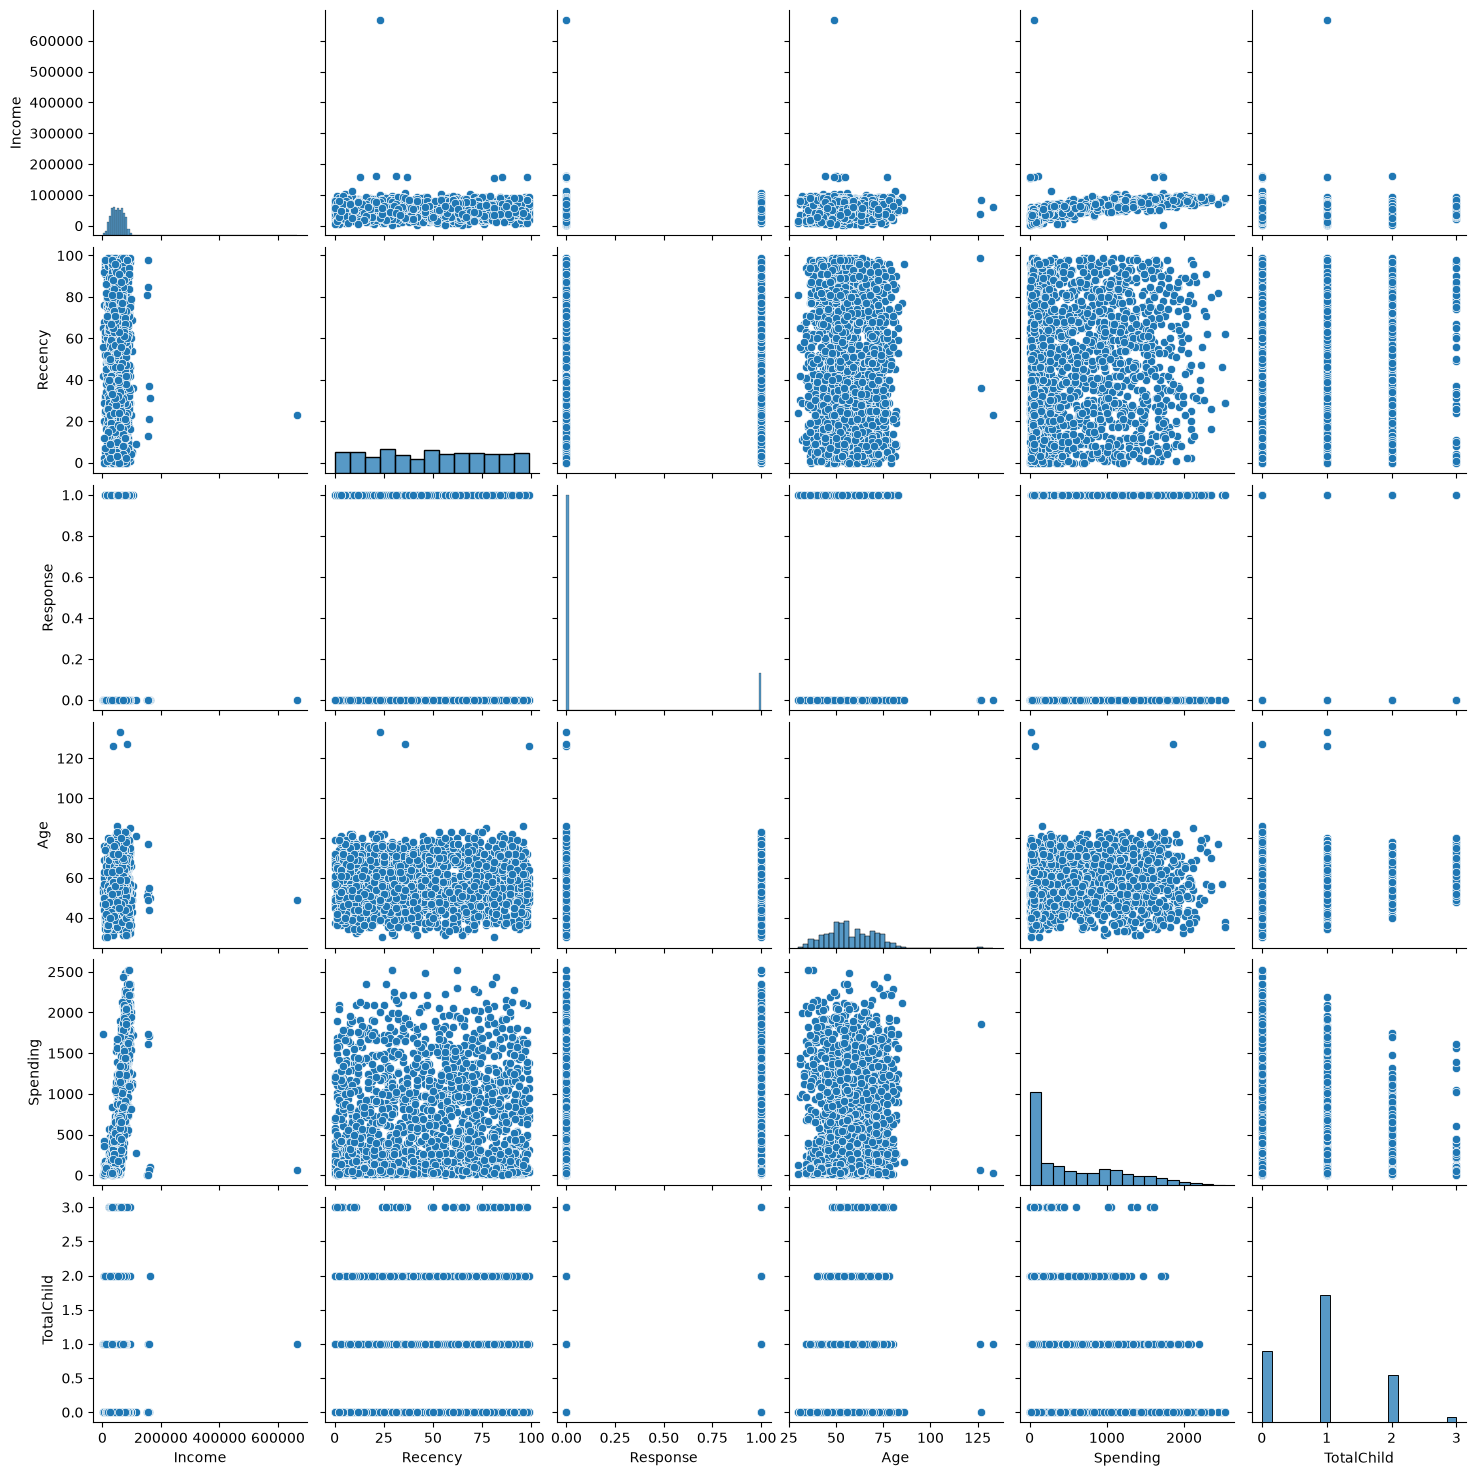

In [9]:
# Handling Outliers 
cols=["Income","Recency","Response","Age","Spending","TotalChild"]


# Plotting 
sns.pairplot(df_cleaned[cols])

In [10]:
# Outliers are Income around 6000000, age = 120 
# remove outliers 
df_cleaned=df_cleaned[df_cleaned["Age"]<90]
df_cleaned=df_cleaned[df_cleaned["Income"]<600000]

<Axes: >

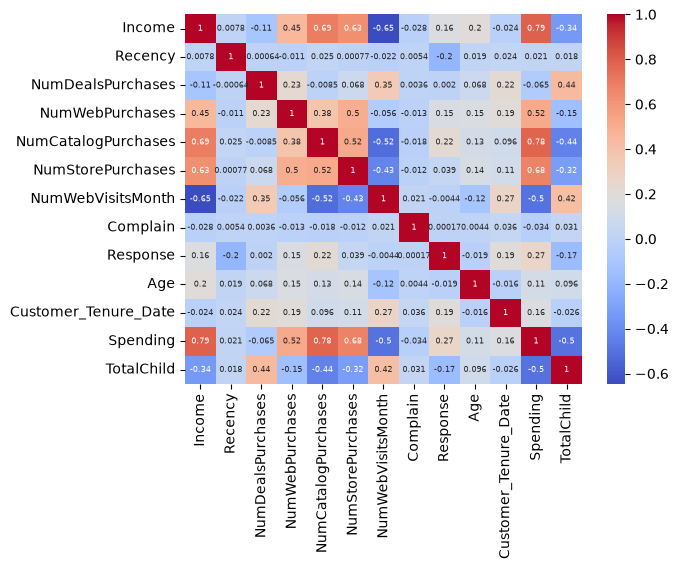

In [11]:
# Identify corelation 
corrm=df_cleaned.corr(numeric_only=True)


sns.heatmap(corrm,cmap="coolwarm",annot_kws={"size":6},annot=True)

In [12]:
# catalog purchase to income , income to total spending , income to store purchases , high income to web visits are less,Spending to catalog , Spending to store purchases 

In [13]:
from sklearn.preprocessing import OneHotEncoder
categorical_cols=["Living_With","Education"]

encoder = OneHotEncoder()
enc_cols=encoder.fit_transform(df_cleaned[categorical_cols])
enc_Df=pd.DataFrame(enc_cols.toarray(),columns=encoder.get_feature_names_out(categorical_cols),index=df_cleaned.index)


In [14]:
df_encoded=pd.concat([df_cleaned.drop(columns=categorical_cols),enc_Df],axis=1)
X=df_encoded

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled=scaler.fit_transform(X)


In [16]:
X_scaled.shape

(2236, 19)

array([0.21946658, 0.10788256, 0.09588641])

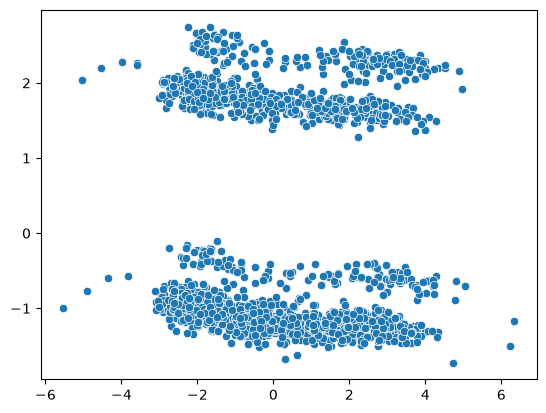

In [17]:
# X.head
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_x=pca.fit_transform(X_scaled)
sns.scatterplot(x=pca_x[:,0],y=pca_x[:,1])
pca.explained_variance_ratio_
# as we can see only 30% data captured so we can inc number of components

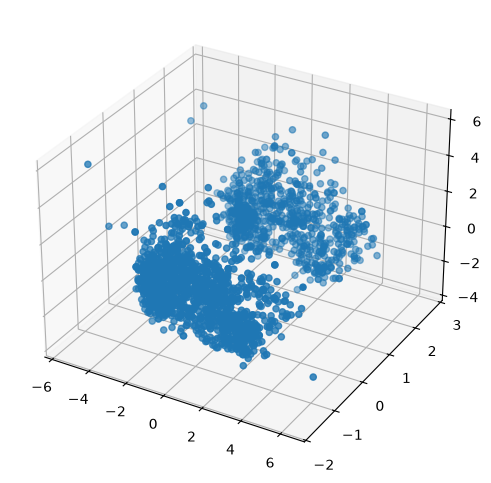

In [18]:
import matplotlib.pyplot as plt 
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")

ax.scatter(pca_x[:,0],pca_x[:,1],pca_x[:,2])


In [20]:
# Now analyze k Value 
from sklearn.cluster import KMeans
from kneed import KneeLocator
wcss=[]
for k in range(1,11):
    kmm=KMeans(n_clusters=k,random_state=42)
    kmm.fit_predict(pca_x)
    wcss.append(kmm.inertia_)
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
best_k=knee.knee
# With silhoutte score 
from sklearn.metrics import silhouette_score
scores=[]
for k in range(2,11):
    kmm=KMeans(n_clusters=k,random_state=42)
    labels=kmm.fit_predict(pca_x)
    score=silhouette_score(pca_x,labels)
    scores.append(score)


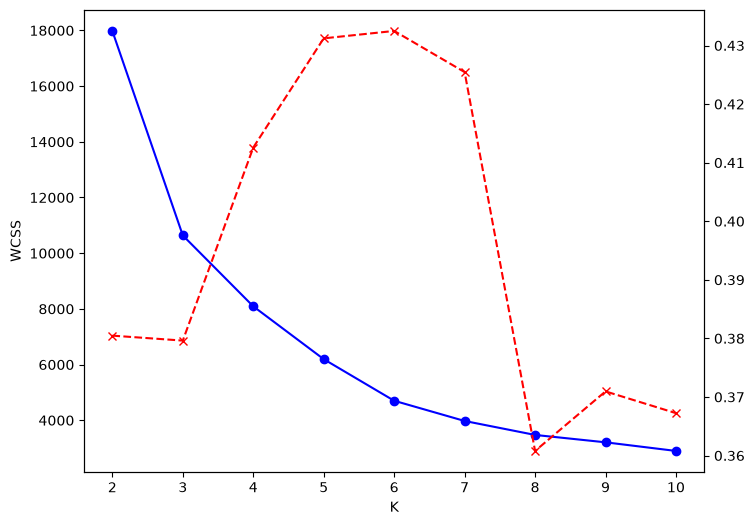

In [21]:
# Combined Ploot 
# combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker="o", color="blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()

ax2.plot(k_range, scores[:len(k_range)], marker="x", color="red", linestyle="--")

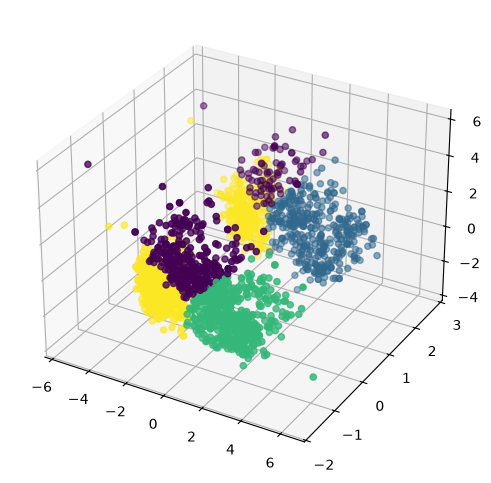

In [22]:
# as they intersect around 4 so we use k = 4 

import matplotlib.pyplot as plt 
kmm=KMeans(n_clusters=4)
labels_kmm=kmm.fit_predict(pca_x)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")

ax.scatter(pca_x[:,0],pca_x[:,1],pca_x[:,2],c=labels_kmm)


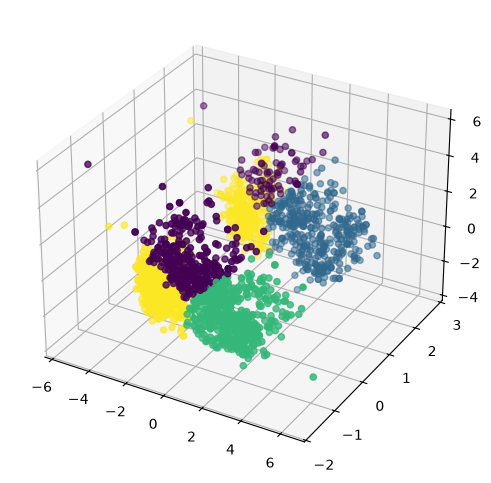

In [23]:
from sklearn.cluster import AgglomerativeClustering
agc = AgglomerativeClustering(n_clusters=4)
labels_agc=agc.fit_predict(pca_x)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")

# Agglomerative CLustering is best as it good visulation of clusters 

ax.scatter(pca_x[:,0],pca_x[:,1],pca_x[:,2],c=labels_kmm)


<Axes: xlabel='clusters', ylabel='count'>

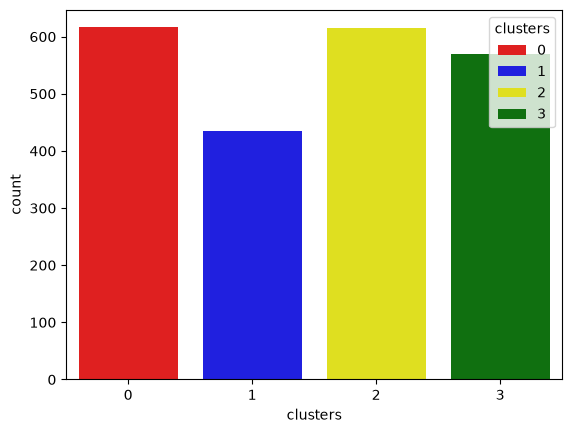

In [24]:
# Characterization  of clusters 
X["clusters"]=labels_agc
df_cleaned.head()

pal=["red","blue","yellow","green"]
sns.countplot(
    x=X["clusters"],
    palette=pal,
    hue=X["clusters"]
)

<Axes: xlabel='Spending', ylabel='Income'>

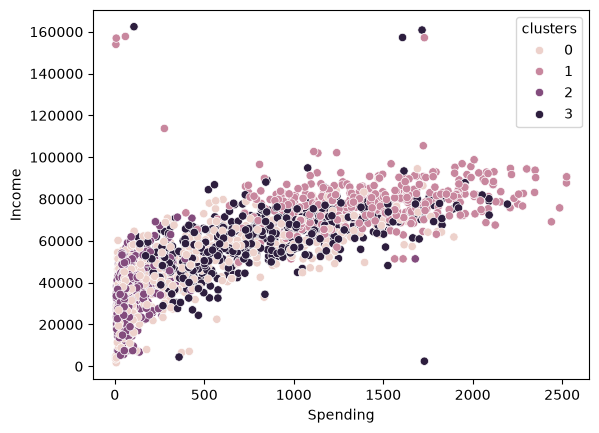

In [25]:
# income and spending patterns
sns.scatterplot(x=X["Spending"],y=X["Income"],hue=X["clusters"])

In [26]:

'''
Cluster 1 ANd CLuster 3 spend high and income is high 
cluster 0 and cluster 2 spend low and income is also low 
'''

X.groupby("clusters").mean()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Date,Spending,TotalChild,Living_With_Alone,Living_With_Partner,Education_Graduate,Education_PhD,Education_Postgraduate,Education_Undergraduate
clusters,,,,,,,,,,,,,,,,,,,
0,44268.955357,47.987013,2.655844,3.892857,1.740260,4.975649,6.232143,0.009740,0.160714,57.243506,365.123377,393.743506,1.154221,0.998377,0.001623,0.498377,0.230519,0.155844,0.115260
1,78763.178161,51.204598,0.967816,4.705747,6.193103,8.471264,2.133333,0.004598,0.275862,57.372414,312.473563,1409.443678,0.068966,0.411494,0.588506,0.549425,0.213793,0.160920,0.075862
2,33711.121951,49.100813,1.865041,1.920325,0.469919,3.156098,6.416260,0.011382,0.061789,53.760976,312.281301,86.591870,1.230894,0.000000,1.000000,0.497561,0.162602,0.154472,0.185366
3,59477.273684,48.759649,3.503509,6.164912,3.333333,7.487719,5.578947,0.008772,0.135088,60.347368,417.792982,782.592982,1.101754,0.000000,1.000000,0.480702,0.263158,0.191228,0.064912


In [27]:
# Co c2more children lower age, avg response   , higher web visits  , store and catalog purchases high , lower purchases 
# c1 c3 higher age high response ,lower web visits, store and catalog purchases high 
c0 are family shoppers : inc engagement with coupons 
c1 : high income high spending : loyalty programs 
c2 : sales / heavy coupon 
c3 : best roi , offre preimum services , loyalty programs 

SyntaxError: invalid syntax (1182048929.py, line 3)